In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/yolo_project'
%cd {PROJECT}

Mounted at /content/drive
/content/drive/MyDrive/yolo_project


In [2]:
!pip install -q ultralytics
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 (런타임 유형 확인!)")

GPU: Tesla T4


In [3]:
import glob, os, yaml
!rm -rf /content/dataset
!unzip -q -o {PROJECT}/dataset.zip -d /content/dataset

yaml_path = glob.glob('/content/dataset/**/data.yaml', recursive=True)[0]
root = os.path.dirname(yaml_path)
with open(yaml_path) as f:
    cfg = yaml.safe_load(f)
cfg['path'] = root
cfg['train'], cfg['val'], cfg['test'] = 'train/images', 'valid/images', 'test/images'
DATA = '/content/data.yaml'
with open(DATA, 'w') as f:
    yaml.safe_dump(cfg, f, allow_unicode=True)

print("클래스:", cfg['names'])
for s in ['train', 'valid', 'test']:
    print(s, len(os.listdir(f'{root}/{s}/images')), '장')

클래스: ['car', 'escooter', 'motorcycle']
train 233 장
valid 65 장
test 33 장


In [4]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')          # COCO로 사전학습된 모델에서 시작
model.train(
    data=DATA,
    epochs=100,
    patience=20,                    # 20 epoch 동안 나아지지 않으면 조기 종료
    imgsz=640,
    batch=16,
    project=f'{PROJECT}/runs',
    name='train',
    exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bf1c6152a50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

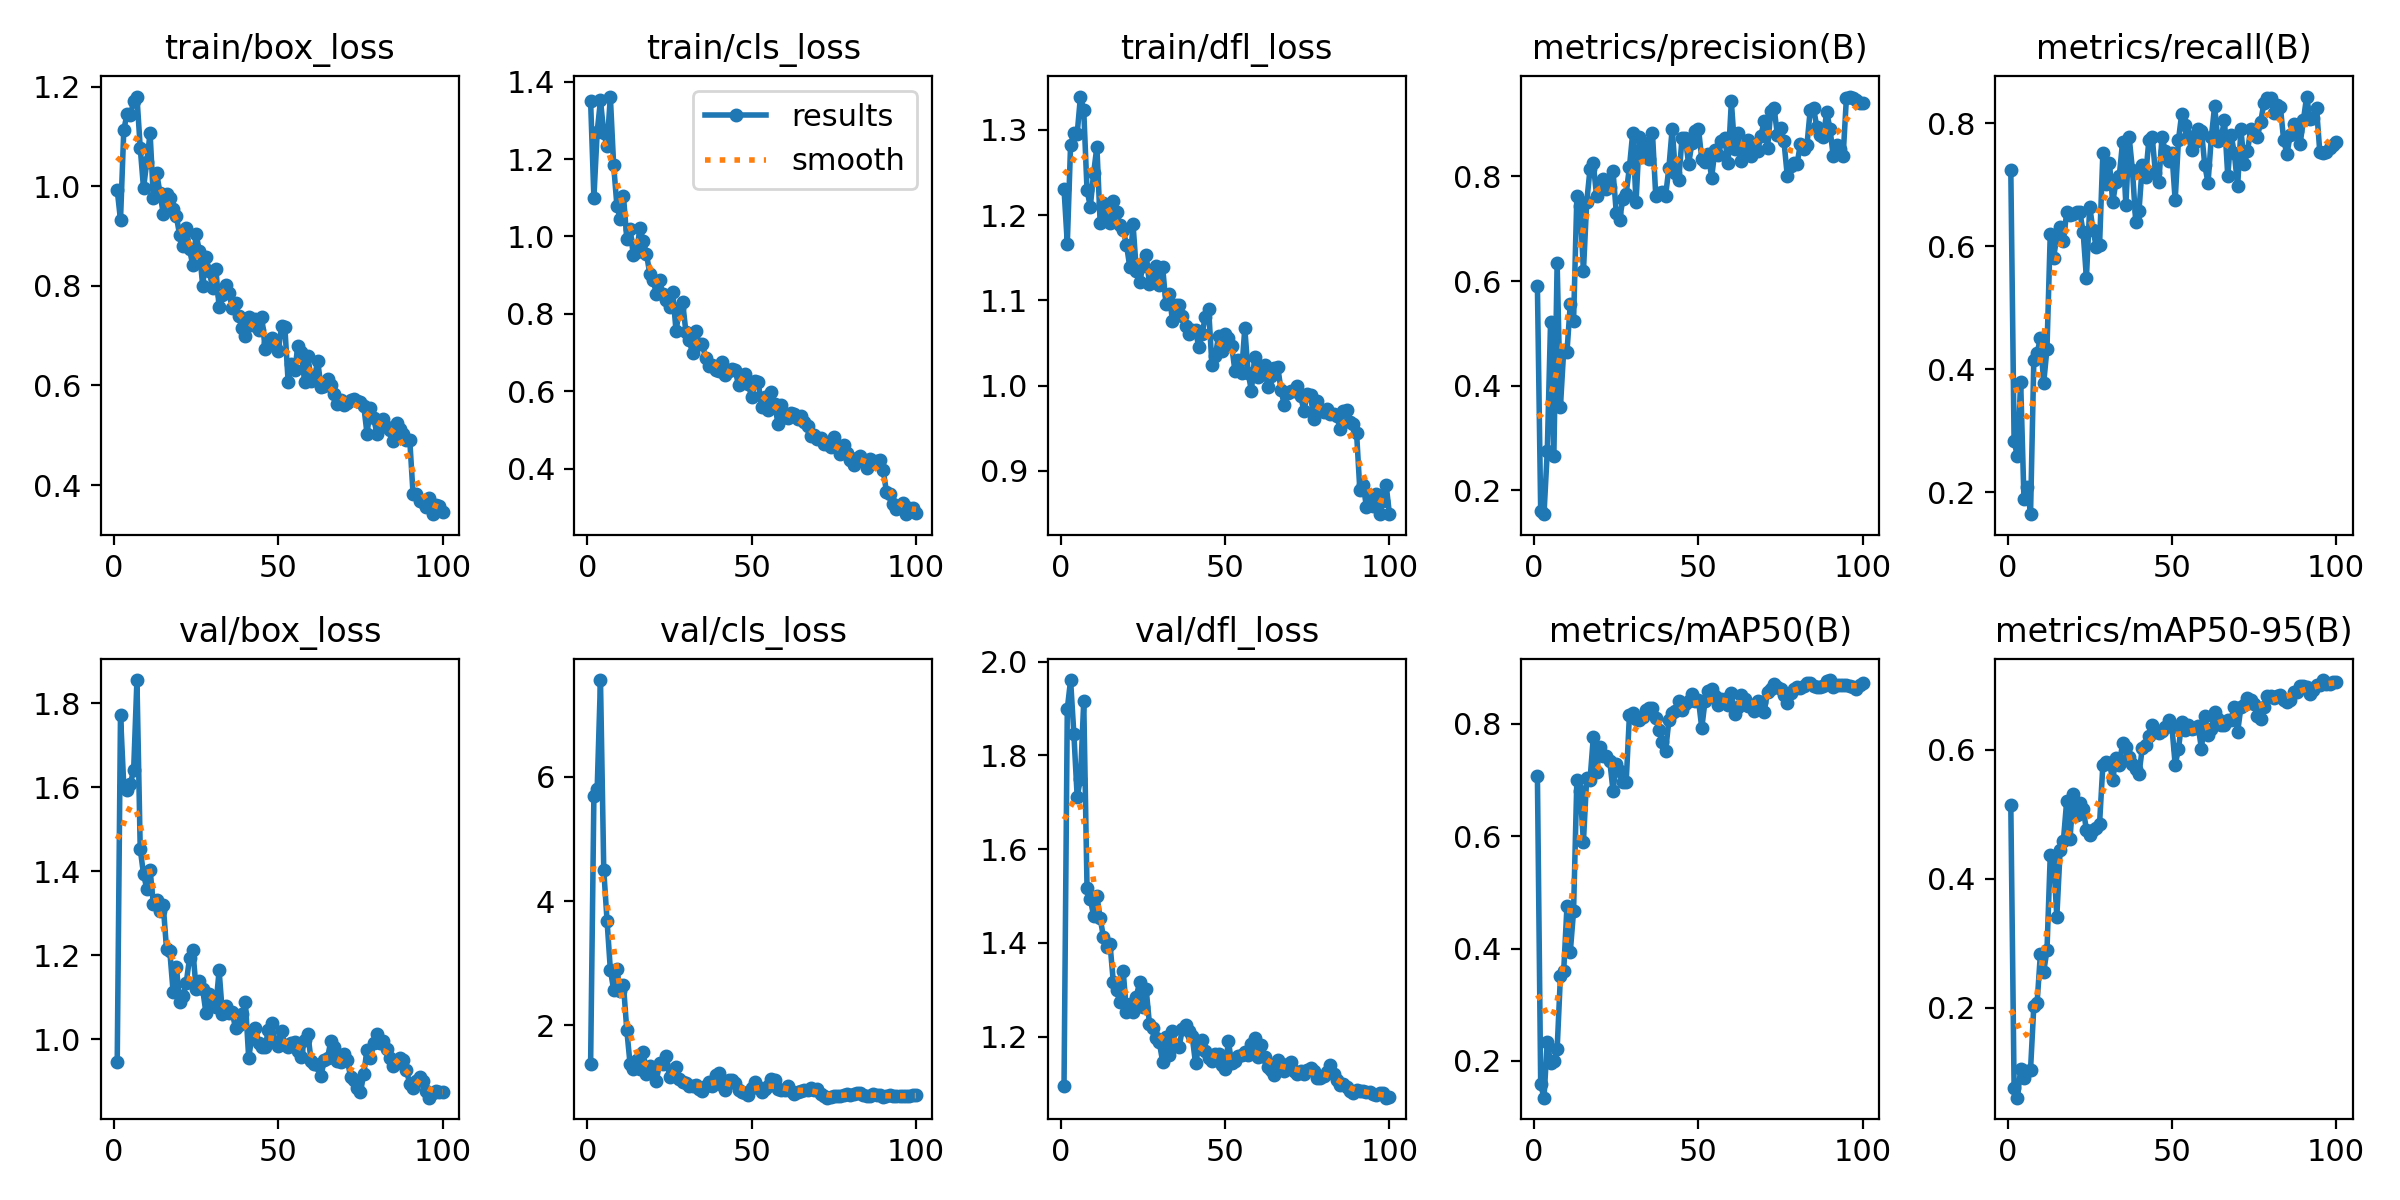

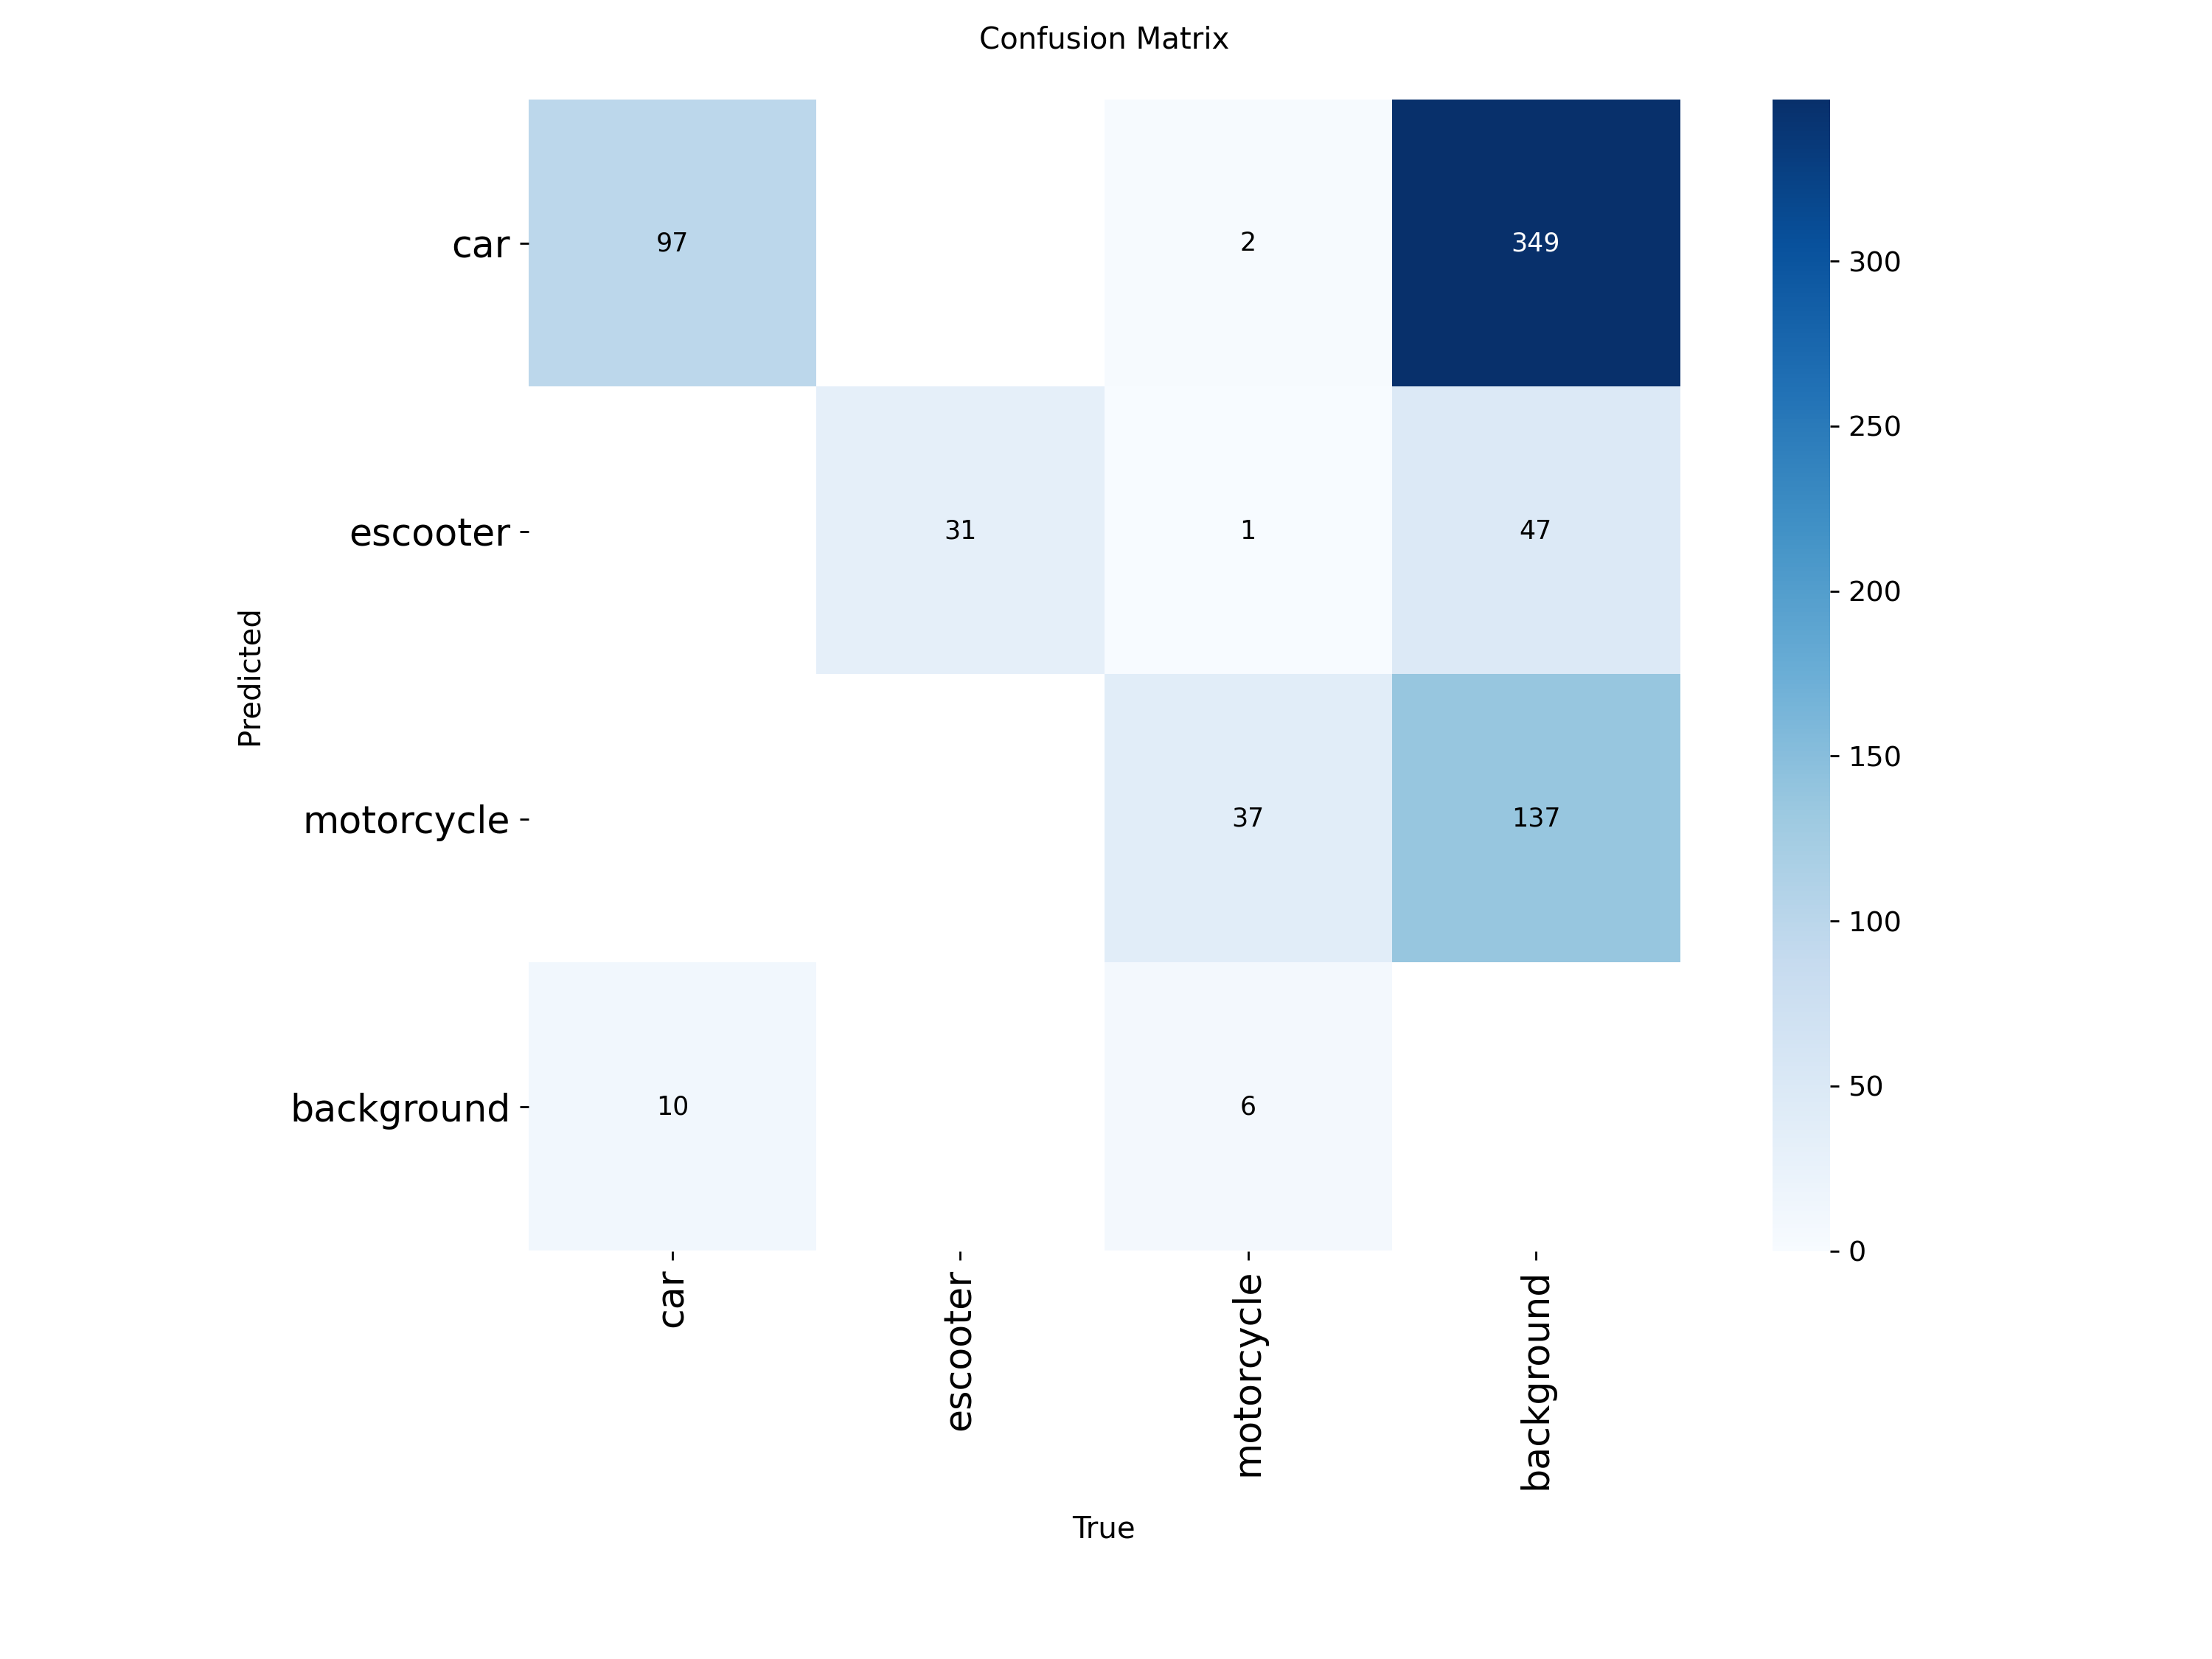

In [5]:
from IPython.display import Image, display
RUN = f'{PROJECT}/runs/train'
display(Image(f'{RUN}/results.png', width=900))
display(Image(f'{RUN}/confusion_matrix.png', width=600))

In [6]:
best = YOLO(f'{RUN}/weights/best.pt')
m = best.val(data=DATA, split='test')
print(f"\n[테스트셋] Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 22.6±19.2 MB/s, size: 65.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dataset/test/labels... 33 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 33/33 314.6it/s 0.1s
val: New cache created: /content/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.8it/s 1.7s
                   all         33         71      0.949      0.861      0.936      0.818
                   car         15         42      0.942      0.643      0.843      0.669
              escooter         12         17      0.986      0.941       0.97      0.894
            motorcycle   

In [7]:
os.makedirs(f'{PROJECT}/results', exist_ok=True)

In [10]:
import cv2, csv
import numpy as np
from collections import defaultdict

CONF = 0.55                     # 신뢰도 임계값 (0.3 → 0.55로 올려 보행자 오인식 제거)
TAG = 'conf055'                 # 저장 파일 이름에 붙일 표시

best.predictor = None           # 이전 실행의 추적 상태 초기화 (ID가 1번부터 다시 시작)

cap = cv2.VideoCapture(f'{PROJECT}/street.mp4')
fps = cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
tmp_path = '/content/tracking_tmp.mp4'
out = cv2.VideoWriter(tmp_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

history = defaultdict(list)
rows = []
frame_idx = 0

while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = best.track(frame, persist=True, tracker='bytetrack.yaml', conf=CONF, verbose=False)[0]
    canvas = r.plot()

    if r.boxes.id is not None:
        xywh = r.boxes.xywh.cpu().numpy()
        ids = r.boxes.id.int().cpu().tolist()
        clss = r.boxes.cls.int().cpu().tolist()
        confs = r.boxes.conf.cpu().tolist()
        for (x, y, bw, bh), tid, c, cf in zip(xywh, ids, clss, confs):
            history[tid].append((int(x), int(y)))
            rows.append([frame_idx, round(frame_idx / fps, 2), tid, best.names[c],
                         round(cf, 3), round(float(x), 1), round(float(y), 1)])
            pts = np.array(history[tid][-60:], dtype=np.int32).reshape(-1, 1, 2)
            color = tuple(int(v) for v in np.random.default_rng(tid).integers(80, 255, 3))
            cv2.polylines(canvas, [pts], False, color, 4)
            cv2.circle(canvas, (int(x), int(y)), 6, color, -1)

    out.write(canvas)
    frame_idx += 1

cap.release(); out.release()

with open(f'{PROJECT}/results/trajectories_{TAG}.csv', 'w', newline='') as f:
    wr = csv.writer(f)
    wr.writerow(['frame', 'time_sec', 'track_id', 'class', 'conf', 'center_x', 'center_y'])
    wr.writerows(rows)

print(f"{frame_idx}프레임 처리, 추적된 객체 {len(history)}개")

125프레임 처리, 추적된 객체 16개


In [12]:
!ffmpeg -y -loglevel error -i {tmp_path} -c:v libx264 -pix_fmt yuv420p -crf 23 {PROJECT}/results/tracking_result_{TAG}.mp4
print("저장 위치:", f'{PROJECT}/results/tracking_result_{TAG}.mp4')

저장 위치: /content/drive/MyDrive/yolo_project/results/tracking_result_conf055.mp4
